# SEM pair potential

This notebook documents the element–element potential of the PhysiCore sub-cellular element model
(`mechanics/micromechanics/include/micromechanics/pair_potential.h`) and shows how each parameter
changes its shape. Use it to choose parameters before running a simulation.

## Definition

With $t(r) = \exp\!\left[\rho\,\left(1 - r^2 / r_\mathrm{eq}^2\right)\right]$:

$$V(r) = u_0\,\left(t^2 - 2t\right) \quad\text{for } r < r_\mathrm{cut}, \qquad V(r) = 0 \text{ otherwise}$$

This is Eq. 2 of SEM² (Chattaraj et al., *APL Bioengineering* 2023) with $\alpha = 2$.

| Symbol | Code name | Meaning |
|---|---|---|
| $u_0$ | `intra_well_depth`, `inter_well_depth` | depth of the energy well |
| $r_\mathrm{eq}$ | `equilibrium_distance` | distance at which two elements neither attract nor repel |
| $\rho$ | `steepness` | dimensionless; larger means stiffer and shorter ranged |
| $r_\mathrm{cut}$ | `cutoff_factor * equilibrium_distance` | interactions are ignored from here on |
| $\eta$ | `drag_coefficient` | element velocity is force / $\eta$ |

Elements of the same cell (*intra*) and of different cells (*inter*) use the same shape and differ only in $u_0$.

## Force and sign convention

The code never takes a square root. It computes a **force coefficient**

$$c(r^2) = -\frac{V'(r)}{r} = \frac{4\,u_0\,\rho}{r_\mathrm{eq}^2}\; t\,(t - 1)$$

and the force on element $i$ due to element $j$ is $\mathbf{F}_i = c\,(\mathbf{x}_i - \mathbf{x}_j)$, with $\mathbf{F}_j = -\mathbf{F}_i$.
So $c > 0$ is **repulsion** ($r < r_\mathrm{eq}$) and $c < 0$ is **adhesion**.
The plots below show the radial force $F(r) = c\,r$, positive = repulsive.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def t_factor(r, r_eq, rho):
    return np.exp(rho * (1.0 - (r / r_eq) ** 2))


def energy(r, u0=1.0, r_eq=1.0, rho=2.0, cutoff_factor=2.5):
    r = np.asarray(r, dtype=float)
    t = t_factor(r, r_eq, rho)
    return np.where(r < cutoff_factor * r_eq, u0 * t * (t - 2.0), 0.0)


def radial_force(r, u0=1.0, r_eq=1.0, rho=2.0, cutoff_factor=2.5):
    # positive = repulsive
    r = np.asarray(r, dtype=float)
    t = t_factor(r, r_eq, rho)
    return np.where(r < cutoff_factor * r_eq, 4.0 * u0 * rho / r_eq**2 * t * (t - 1.0) * r, 0.0)

## Check against the C++ implementation

The functions above are a second copy of the maths, so they are checked against numbers produced by the
C++ code. `data/pair_potential_reference.csv` is the output of the example executable with default parameters:

```bash
build/gcc-debug/mechanics/micromechanics/examples/mechanics.micromechanics.potential_curve \
    > mechanics/micromechanics/docs/notebooks/data/pair_potential_reference.csv
```

Regenerate it whenever `pair_potential.h` changes. If the cell below fails, this notebook no longer
describes the implementation.

In [2]:
reference_file = Path("data/pair_potential_reference.csv")

header = reference_file.read_text().splitlines()[0]
reference_params = {key: float(value) for key, value in (item.split("=") for item in header.lstrip("# ").split())}
reference = np.genfromtxt(reference_file, delimiter=",", names=True, skip_header=1)

shape = dict(
    r_eq=reference_params["equilibrium_distance"],
    rho=reference_params["steepness"],
    cutoff_factor=reference_params["cutoff_factor"],
)
# samples within rounding distance of the cutoff may fall on either side of it
away_from_cutoff = np.abs(reference["r"] - shape["cutoff_factor"] * shape["r_eq"]) > 1e-9
r_ref = reference["r"][away_from_cutoff]

for kind in ("intra", "inter"):
    u0 = reference_params[f"{kind}_well_depth"]
    np.testing.assert_allclose(energy(r_ref, u0, **shape), reference[f"{kind}_energy"][away_from_cutoff], rtol=1e-10, atol=1e-12)
    np.testing.assert_allclose(radial_force(r_ref, u0, **shape), reference[f"{kind}_force"][away_from_cutoff], rtol=1e-10, atol=1e-12)

print(f"Python formulas agree with the C++ output at {r_ref.size} distances.")
print("Reference parameters:", reference_params)

Python formulas agree with the C++ output at 301 distances.
Reference parameters: {'equilibrium_distance': 1.0, 'steepness': 2.0, 'intra_well_depth': 1.0, 'inter_well_depth': 0.5, 'cutoff_factor': 2.5}


## Shape of the potential

Landmarks, all exact:

- **Minimum** at $r = r_\mathrm{eq}$, where $V = -u_0$ and $F = 0$.
- **Zero energy** at $r_0 = r_\mathrm{eq}\sqrt{1 - \ln 2/\rho}$ (needs $\rho > \ln 2$).
- **At contact** ($r = 0$) the energy is finite, $V(0) = u_0\,e^{\rho}(e^{\rho} - 2)$, and the force is zero:
  two coincident elements have no direction to separate along. The repulsion is soft, not a hard core.

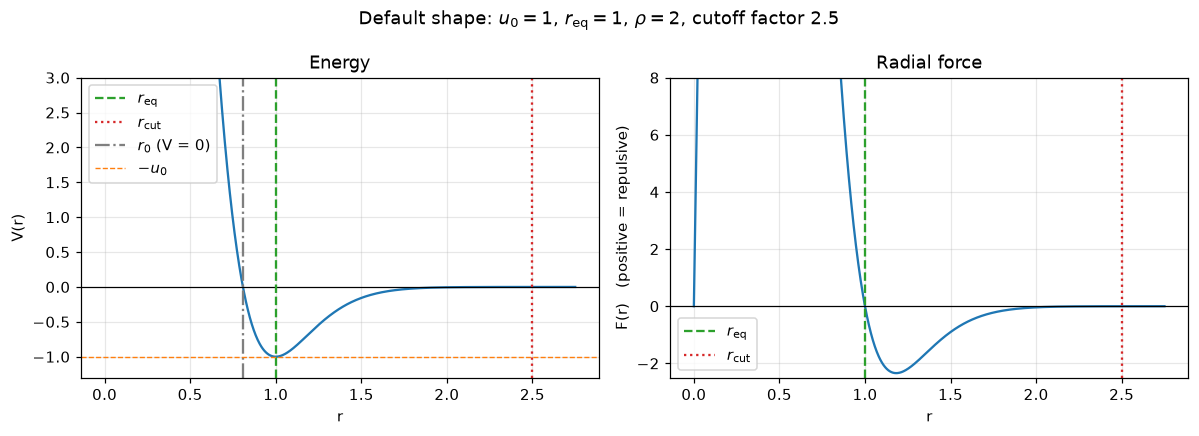

In [3]:
def plot_potential(ax_v, ax_f, r, label=None, **params):
    ax_v.plot(r, energy(r, **params), label=label)
    ax_f.plot(r, radial_force(r, **params), label=label)


def decorate(ax_v, ax_f, v_limits=(-1.3, 3.0), f_limits=(-2.5, 8.0)):
    ax_v.set(xlabel="r", ylabel="V(r)", title="Energy", ylim=v_limits)
    ax_f.set(xlabel="r", ylabel="F(r)   (positive = repulsive)", title="Radial force", ylim=f_limits)
    for ax in (ax_v, ax_f):
        ax.axhline(0.0, color="black", linewidth=0.8)


r = np.linspace(0.0, 2.75, 1200)
u0, r_eq, rho, cutoff_factor = 1.0, 1.0, 2.0, 2.5

fig, (ax_v, ax_f) = plt.subplots(1, 2, figsize=(11, 4))
plot_potential(ax_v, ax_f, r, u0=u0, r_eq=r_eq, rho=rho, cutoff_factor=cutoff_factor)
decorate(ax_v, ax_f)

r_zero = r_eq * np.sqrt(1.0 - np.log(2.0) / rho)
for ax in (ax_v, ax_f):
    ax.axvline(r_eq, color="tab:green", linestyle="--", label=r"$r_\mathrm{eq}$")
    ax.axvline(cutoff_factor * r_eq, color="tab:red", linestyle=":", label=r"$r_\mathrm{cut}$")
ax_v.axvline(r_zero, color="tab:gray", linestyle="-.", label=r"$r_0$ (V = 0)")
ax_v.axhline(-u0, color="tab:orange", linestyle="--", linewidth=0.9, label=r"$-u_0$")
ax_v.legend()
ax_f.legend()
fig.suptitle(r"Default shape: $u_0 = 1$, $r_\mathrm{eq} = 1$, $\rho = 2$, cutoff factor 2.5")
fig.tight_layout()

## Effect of each parameter

One parameter is varied per row; the others stay at $u_0 = 1$, $r_\mathrm{eq} = 1$, $\rho = 2$.

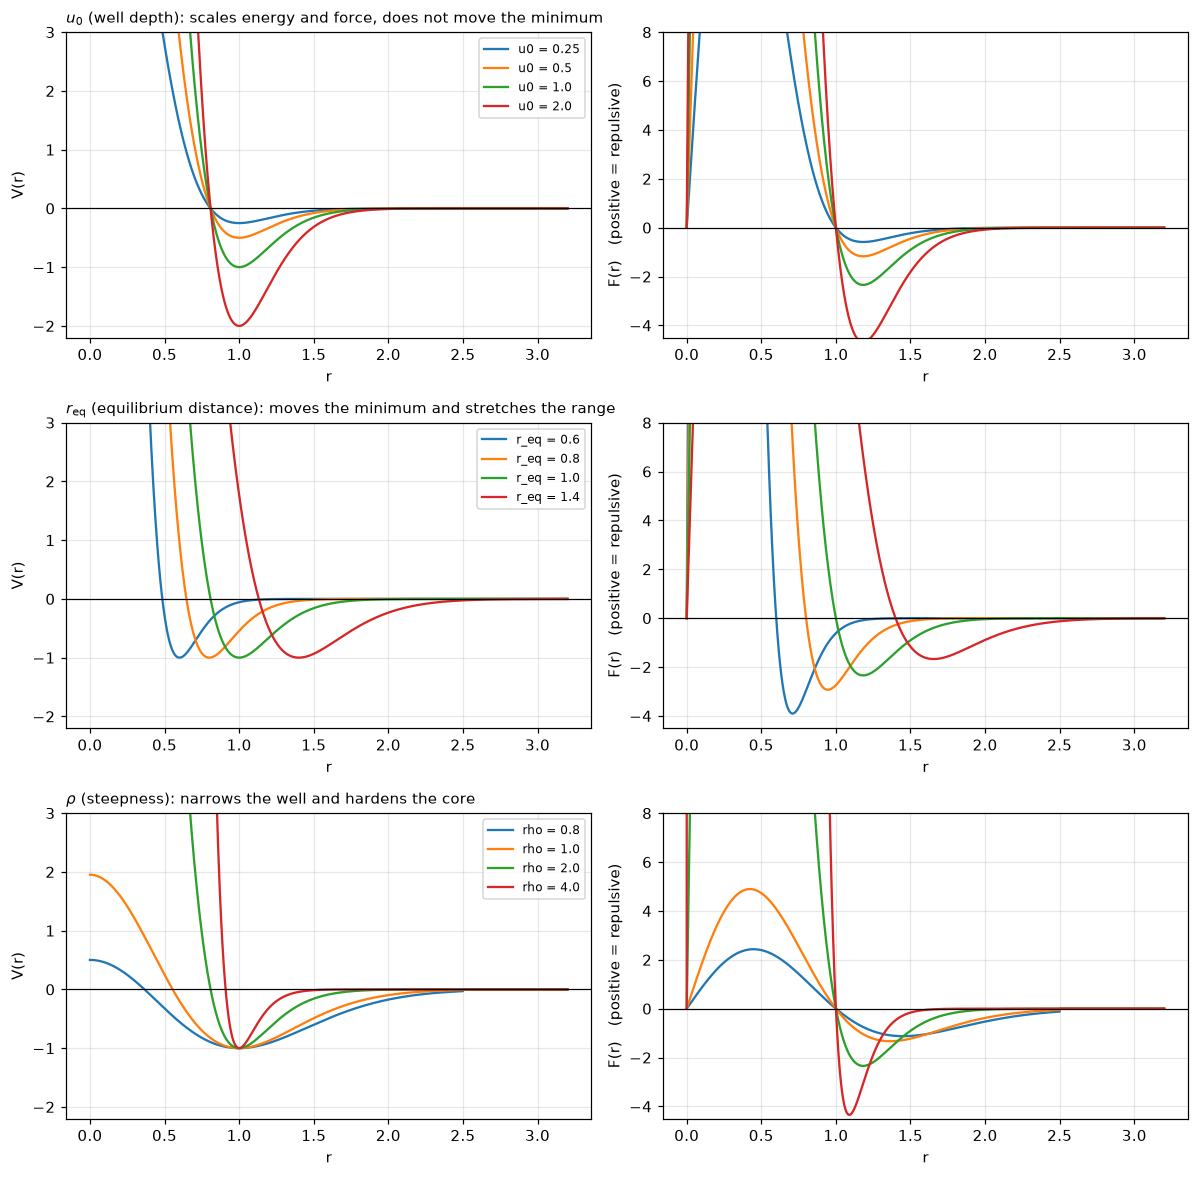

In [4]:
sweeps = [
    ("u0", r"$u_0$ (well depth): scales energy and force, does not move the minimum", [0.25, 0.5, 1.0, 2.0]),
    ("r_eq", r"$r_\mathrm{eq}$ (equilibrium distance): moves the minimum and stretches the range", [0.6, 0.8, 1.0, 1.4]),
    ("rho", r"$\rho$ (steepness): narrows the well and hardens the core", [0.8, 1.0, 2.0, 4.0]),
]

fig, axes = plt.subplots(len(sweeps), 2, figsize=(11, 3.6 * len(sweeps)))
r = np.linspace(0.0, 3.2, 1500)

for (name, title, values), (ax_v, ax_f) in zip(sweeps, axes):
    for value in values:
        params = dict(u0=1.0, r_eq=1.0, rho=2.0, cutoff_factor=2.5)
        params[name] = value
        plot_potential(ax_v, ax_f, r, label=f"{name} = {value}", **params)
    decorate(ax_v, ax_f, v_limits=(-2.2, 3.0), f_limits=(-4.5, 8.0))
    ax_v.set_title("")
    ax_v.set_title(title, loc="left", fontsize=10)
    ax_f.set_title("")
    ax_v.legend(fontsize=8)

fig.tight_layout()

### The cutoff

The potential is truncated, not shifted, so energy and force jump to zero at $r_\mathrm{cut}$.
The size of that jump relative to $u_0$ depends only on $\rho$ and the cutoff factor.
A jump that is not negligible makes elements feel a kick whenever a pair crosses the cutoff.

Default (rho = 2, factor 2.5): jump = 5.51e-05 u0


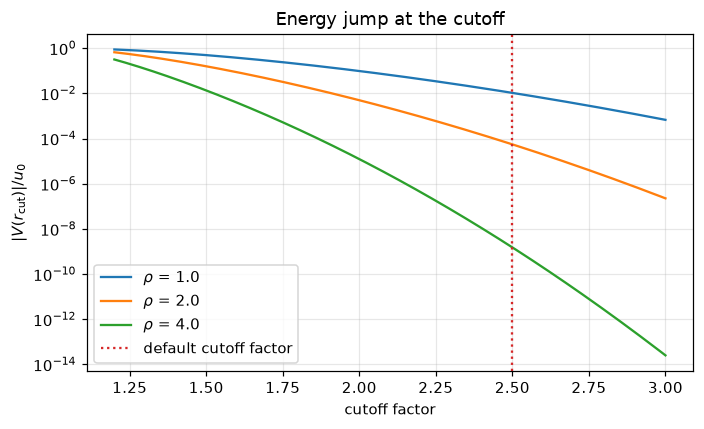

In [5]:
cutoff_factors = np.linspace(1.2, 3.0, 200)

fig, ax = plt.subplots(figsize=(6.5, 4))
for rho in (1.0, 2.0, 4.0):
    just_inside = cutoff_factors * (1.0 - 1e-12)
    ax.semilogy(cutoff_factors, np.abs(energy(just_inside, rho=rho, cutoff_factor=10.0)), label=rf"$\rho$ = {rho}")
ax.axvline(2.5, color="tab:red", linestyle=":", label="default cutoff factor")
ax.set(xlabel="cutoff factor", ylabel=r"$|V(r_\mathrm{cut})| / u_0$", title="Energy jump at the cutoff")
ax.legend()
fig.tight_layout()

print(f"Default (rho = 2, factor 2.5): jump = {abs(float(energy(2.5 * (1 - 1e-12), cutoff_factor=10.0))):.2e} u0")

## Intra- versus inter-cellular

A cell holds together because its own elements bind to each other more strongly than to elements of
other cells. Both wells sit at the same distance; only the depth differs.
The ratio `inter_well_depth / intra_well_depth` is the main knob for how sticky cells are to one another.

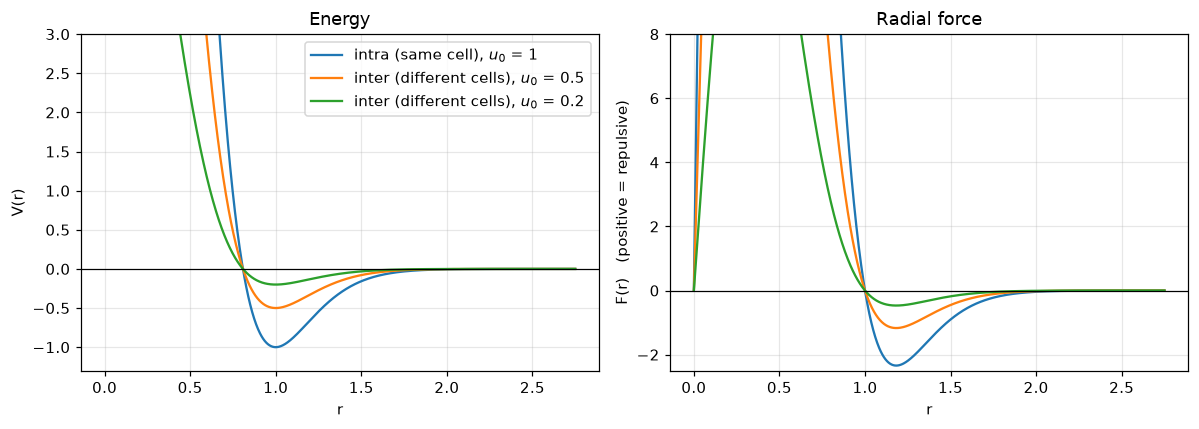

In [6]:
fig, (ax_v, ax_f) = plt.subplots(1, 2, figsize=(11, 4))
r = np.linspace(0.0, 2.75, 1200)

plot_potential(ax_v, ax_f, r, label="intra (same cell), $u_0$ = 1", u0=1.0)
for ratio in (0.5, 0.2):
    plot_potential(ax_v, ax_f, r, label=f"inter (different cells), $u_0$ = {ratio}", u0=ratio)
decorate(ax_v, ax_f)
ax_v.legend()
fig.tight_layout()

## Derived quantities for choosing parameters

- **Stiffness at the minimum:** $k = V''(r_\mathrm{eq}) = 8\,u_0\,\rho^2 / r_\mathrm{eq}^2$.
  Near equilibrium a pair behaves like a spring with this constant.
- **Strongest adhesion:** the most negative force and the distance where it occurs. Pulling a pair
  beyond that distance meets decreasing resistance, so this is the force needed to separate two elements.
- **Timestep limit (forward Euler):** for an isolated pair the separation obeys
  $\dot r = 2F(r)/\eta$, which near equilibrium relaxes at rate $2k/\eta$. Forward Euler is stable for
  $\Delta t < \eta / k$ and free of overshoot for $\Delta t < \eta / (2k)$.
  An element with several neighbours feels a larger total stiffness, so in a packed cell the limit is
  lower; treat $\eta/k$ as an upper bound, not a recommendation.

In [7]:
def derived_quantities(u0=1.0, r_eq=1.0, rho=2.0, cutoff_factor=2.5, eta=1.0):
    r = np.linspace(r_eq, cutoff_factor * r_eq, 200001)[:-1]
    force = radial_force(r, u0, r_eq, rho, cutoff_factor)
    strongest = int(np.argmin(force))
    stiffness = 8.0 * u0 * rho**2 / r_eq**2
    return {
        "stiffness k": stiffness,
        "strongest adhesion |F|": -force[strongest],
        "at distance": r[strongest],
        "Euler limit eta/k": eta / stiffness,
    }


parameter_sets = {
    "intra, default": dict(u0=1.0),
    "inter, default": dict(u0=0.5),
    "softer (rho = 1)": dict(u0=1.0, rho=1.0),
    "stiffer (rho = 4)": dict(u0=1.0, rho=4.0),
}

print(f"{'parameter set':<20}{'k':>10}{'max |F_adh|':>14}{'at r':>9}{'eta/k':>10}")
for name, params in parameter_sets.items():
    q = derived_quantities(**params)
    print(f"{name:<20}{q['stiffness k']:>10.3f}{q['strongest adhesion |F|']:>14.4f}{q['at distance']:>9.3f}{q['Euler limit eta/k']:>10.4f}")

parameter set                k   max |F_adh|     at r     eta/k
intra, default          32.000        2.3422    1.182    0.0312
inter, default          16.000        1.1711    1.182    0.0625
softer (rho = 1)         8.000        1.3316    1.364    0.1250
stiffer (rho = 4)      128.000        4.3456    1.090    0.0078


### The timestep limit in action

Two elements start slightly compressed and relax under forward Euler with $\eta = 1$ and the default
potential ($k = 32$, so $\eta/k = 0.03125$).

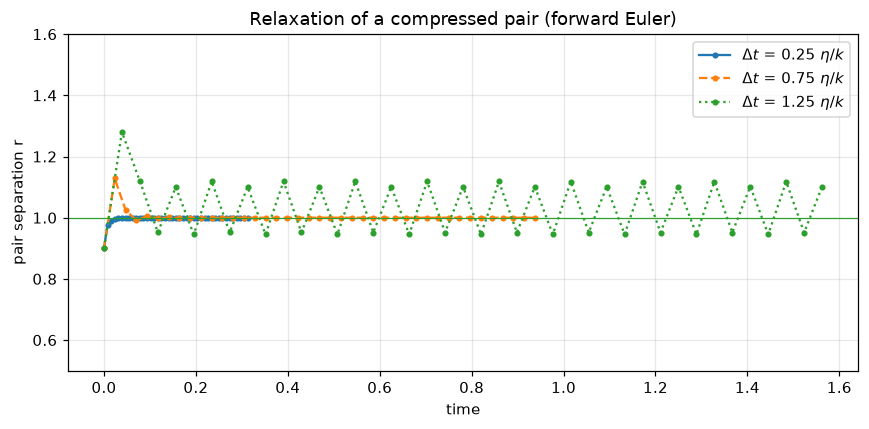

In [8]:
def relax_pair(dt, steps, r_start=0.9, eta=1.0, **params):
    r = np.empty(steps + 1)
    r[0] = r_start
    for n in range(steps):
        # each element moves by F/eta * dt, in opposite directions
        r[n + 1] = abs(r[n] + 2.0 * float(radial_force(r[n], **params)) / eta * dt)
    return r


limit = 1.0 / 32.0
fig, ax = plt.subplots(figsize=(8, 4))
for factor, style in ((0.25, "-"), (0.75, "--"), (1.25, ":")):
    dt = factor * limit
    trajectory = relax_pair(dt, steps=40)
    ax.plot(np.arange(trajectory.size) * dt, trajectory, style, marker=".", label=rf"$\Delta t$ = {factor} $\eta/k$")
ax.axhline(1.0, color="tab:green", linewidth=0.8)
ax.set(xlabel="time", ylabel="pair separation r", title="Relaxation of a compressed pair (forward Euler)", ylim=(0.5, 1.6))
ax.legend()
fig.tight_layout()

assert abs(relax_pair(0.25 * limit, 200)[-1] - 1.0) < 1e-9, "a small timestep must converge to r_eq"
assert abs(relax_pair(1.25 * limit, 200)[-1] - 1.0) > 1e-3, "a timestep above eta/k must not converge"

## Summary

- $u_0$ sets how strongly elements bind; use a smaller value between cells than within a cell.
- $r_\mathrm{eq}$ sets the element spacing and with it the size of a cell for a given number of elements.
- $\rho$ trades softness against range: small $\rho$ gives a wide, soft well; large $\rho$ a narrow, stiff one
  that needs a smaller timestep.
- Keep the cutoff factor large enough that the jump at the cutoff is negligible for the chosen $\rho$.
- Check $\Delta t$ against $\eta/k$ before running, and expect to need a margin below it.

Not covered here because the model does not have them yet: thermal noise, scaling the parameters with the
number of elements per cell, and per-type parameters.